# Activity 5: Building the dataset

We put Trinidad and Tobago's quarterly real GDP together with three high-frequency
sources from the earlier activities and the oil price:

| Source | File | Frequency |
|---|---|---|
| Real GDP (CBTT, constant prices) | `data/gdp.csv` | quarterly |
| Google Trends (25 search terms) | `data/gtrends.csv` | monthly |
| Night-time lights, country mean | `data/ntl_shape.csv` | daily |
| Brent oil price (EIA) | `data/eia_brent.csv` | daily |

Steps: load → clean → seasonally adjust **each series at its own frequency** → merge to
quarterly → growth rates → a first OLS. Then the question that matters: does the
relationship survive without 2020?

Kernel: `nwcst`. Cells marked `# YOUR CODE HERE` are yours.

In [1]:
# ===========================================================================
# CONFIG LOADER  --  edit config.py, NOT this cell.
# Gives you `cfg` (every setting) and `P` (the standard folders).
# ===========================================================================
import os, sys, importlib.util

# config.py lives in activity/. From activity/ that is the current folder;
# from sols/ it is next door.
CODE_DIR = os.getcwd()
if not os.path.exists(os.path.join(CODE_DIR, "config.py")):
    CODE_DIR = os.path.abspath(os.path.join(CODE_DIR, "..", "activity"))
sys.path.insert(0, CODE_DIR)       # so `import nwcst_helpers` works from sols/ too

_spec = importlib.util.spec_from_file_location("config", os.path.join(CODE_DIR, "config.py"))
cfg = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(cfg)
P = cfg.derive_paths(CODE_DIR)     # raw/, data/, output/ under public/

print(f"[CONFIG] {cfg.COUNTRY} ({cfg.CODE})  data -> {P['data']}")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

[CONFIG] Trinidad and Tobago (TT)  data -> C:\Users\guerr\Dropbox\02_Work\Consulting\2026_NWCST_CAR_Research-Workshop\trinidad\public\data


## 1. GDP

`gdp.csv` stamps each quarter on its **last** month (2026Q1 = `2026-03-01`).

In [2]:
gdp = pd.read_csv(os.path.join(P["data"], cfg.GDP_CSV), index_col="date", parse_dates=True)
gdp = gdp.rename(columns={"rgdp": "RGDP0000"})
print(gdp.index.min().date(), "->", gdp.index.max().date(), f"({len(gdp)} quarters)")
gdp.tail()

2012-03-01 -> 2026-03-01 (57 quarters)


,RGDP0000
date,
2025-03-01,35286.342226
2025-06-01,36811.895707
2025-09-01,37594.126550
2025-12-01,37703.621567
2026-03-01,34645.058555


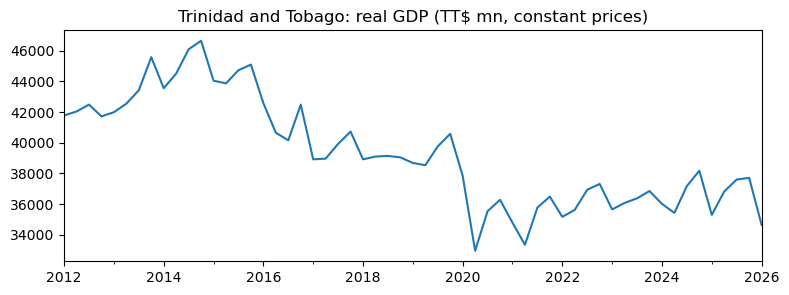

In [3]:
ax = gdp["RGDP0000"].plot(figsize=(9, 3), title="Trinidad and Tobago: real GDP (TT$ mn, constant prices)")
ax.set_xlabel("");

GDP is **not** seasonally adjusted. With quarterly data one seasonal cycle is **4**
observations, so `period=4`.

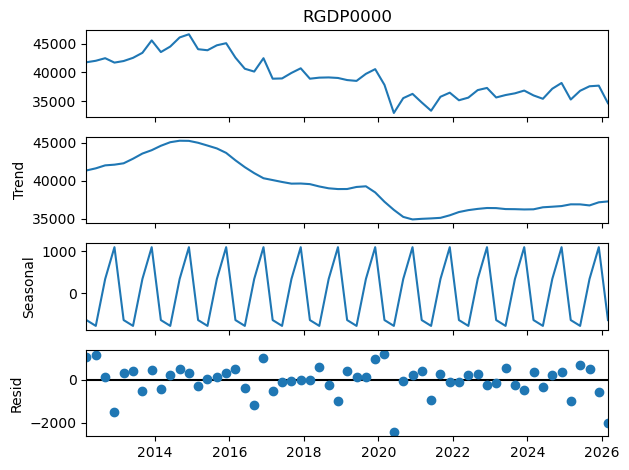

In [4]:
seasonal_decompose(gdp["RGDP0000"], model="additive", extrapolate_trend="freq", period=4).plot();

In [5]:
gdp["RGDP0000"] = gdp["RGDP0000"] - seasonal_decompose(
    gdp["RGDP0000"], model="additive", extrapolate_trend="freq", period=4).seasonal

## 2. Google Trends

A zero in Google Trends usually means *too few searches to report*, not *no interest*, so
we treat zeros as missing, drop terms that are mostly missing, and average the rest into
one index.

21 terms kept: aldo_tt, caribbean_jobs_tt, amazon_tt, payless_tt, rbc_tt, first_citizens_bank_tt, tobago_tt, tobago_ferry_tt, maracas_tt, kfc_tt, pizza_boys_tt, island_finance_tt, tobago_hotel_tt, tgif_tt, huawei_tt, linkedin_tt, flights_miami_tt, disney_world_tt, restaurants_tt, pricesmart_tt, flights_trinidad_worldwide


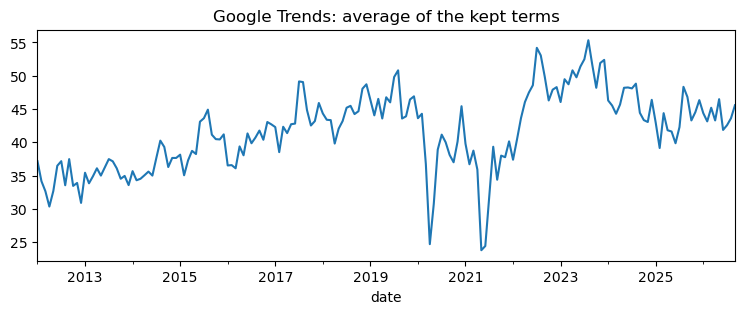

In [6]:
gt = pd.read_csv(os.path.join(P["data"], cfg.GTRENDS_CSV), index_col="date", parse_dates=True)
gt = gt.loc["2012-01-01":]                       # same window as the night lights
gt = gt.replace(0, np.nan)
gt = gt.dropna(axis=1, thresh=int(0.75 * len(gt)))   # keep terms with >= 75% of months
print(gt.shape[1], "terms kept:", ", ".join(c.replace("gtrends_", "") for c in gt.columns))
gt["gt_mean"] = gt.mean(axis=1)
gt["gt_mean"].plot(figsize=(9, 3), title="Google Trends: average of the kept terms");

**Exercise 1.** Seasonally adjust `gt_mean` (monthly, so `period=12`) and plot the raw and adjusted series together.

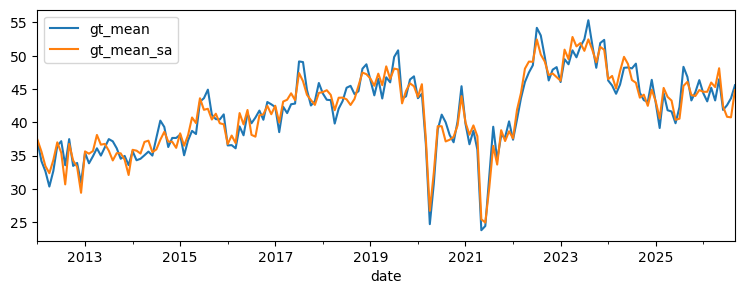

In [7]:
gt["gt_mean_sa"] = gt["gt_mean"] - seasonal_decompose(
    gt["gt_mean"].dropna(), model="additive", extrapolate_trend="freq", period=12).seasonal
gt[["gt_mean", "gt_mean_sa"]].plot(figsize=(9, 3));

In [8]:
gt = gt[["gt_mean_sa"]].rename(columns={"gt_mean_sa": "gt_mean"})

## 3. Night-time lights

The country-mean radiance from Activity 3 is **daily**. Cloudy nights leave gaps, so we
average to months first.

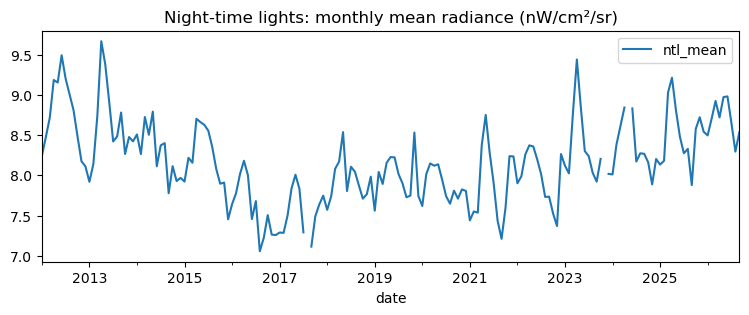

In [9]:
ntl = pd.read_csv(os.path.join(P["data"], cfg.NTL_CSV), index_col="date", parse_dates=True)
ntl = ntl[["shape_mean"]].resample("MS").mean().rename(columns={"shape_mean": "ntl_mean"})
ntl = ntl.loc[:"2026-09-01"]                     # the current month is incomplete
ntl.plot(figsize=(9, 3), title="Night-time lights: monthly mean radiance (nW/cm²/sr)");

**Exercise 2.** Seasonally adjust `ntl_mean` exactly as you did for Google Trends.

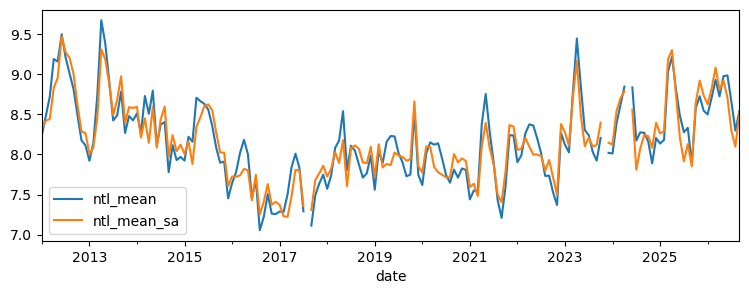

In [10]:
ntl["ntl_mean_sa"] = ntl["ntl_mean"] - seasonal_decompose(
    ntl["ntl_mean"].dropna(), model="additive", extrapolate_trend="freq", period=12).seasonal
ntl.plot(figsize=(9, 3));

In [11]:
ntl = ntl[["ntl_mean_sa"]].rename(columns={"ntl_mean_sa": "ntl_mean"})

## 4. Brent oil price

Trinidad and Tobago is an energy exporter, so the oil price is a natural candidate. The EIA
series in `data/eia_brent.csv` is **daily**; we average it to months. Prices are not
seasonally adjusted.

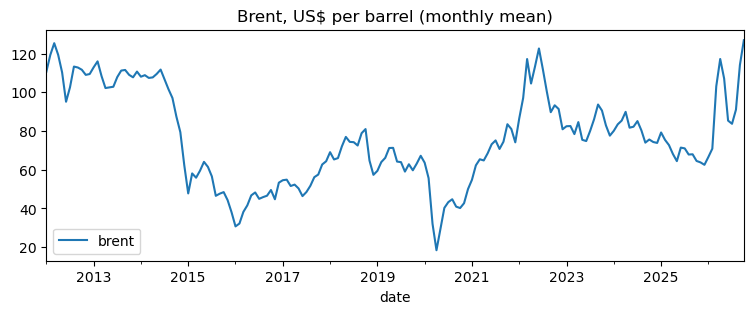

In [12]:
brent = pd.read_csv(os.path.join(P["data"], "eia_brent.csv"), index_col="date", parse_dates=True)
brent = brent.rename(columns={"brent price": "brent"}).resample("MS").mean().loc["2012":]
brent.plot(figsize=(9, 3), title="Brent, US$ per barrel (monthly mean)");

## 5. Merge to quarterly

Monthly series become quarterly by averaging the three months. `resample("QS")` labels a
quarter by its first month, so we shift GDP's stamp (last month) to the same label first.

In [13]:
gdp_q = gdp.copy()
gdp_q.index = gdp_q.index.to_period("Q").to_timestamp()      # 2026-03-01 -> 2026-01-01

monthly = pd.concat([gt, ntl, brent], axis=1)

**Exercise 3.** Resample `monthly` to quarters (`"QS"`) using the mean, then join it with `gdp_q`.

In [14]:
quarterly = monthly.resample("QS").mean()
data = pd.concat([gdp_q, quarterly], axis=1)

In [15]:
data = data.loc[:gdp_q.index.max()]          # stop at the last published GDP quarter
data.tail(8)

,RGDP0000,gt_mean,ntl_mean,brent
date,,,,
2024-04-01,36201.742740,48.753764,8.671288,84.643429
2024-07-01,36832.126676,45.329984,8.040826,79.841649
2024-10-01,37073.912791,43.838826,8.233716,74.612449
2025-01-01,35932.385470,42.966314,8.577811,75.813771
2025-04-01,37596.737753,42.483923,8.751941,68.010754
2025-07-01,37258.719808,44.028397,7.963951,68.965586
2025-10-01,36608.143019,44.299143,8.764030,63.628255
2026-01-01,35291.101800,45.045679,8.838764,80.207975


## 6. Growth rates

Quarter-on-quarter growth, in percent.

In [16]:
growth = data.pct_change(fill_method=None).mul(100)
growth.tail()

,RGDP0000,gt_mean,ntl_mean,brent
date,,,,
2025-01-01,-3.079058,-1.990271,4.179086,1.610082
2025-04-01,4.631900,-1.122719,2.030007,-10.292347
2025-07-01,-0.899062,3.635431,-9.003598,1.403943
2025-10-01,-1.746106,0.614935,10.046252,-7.739123
2026-01-01,-3.597673,1.685216,0.852743,26.057167


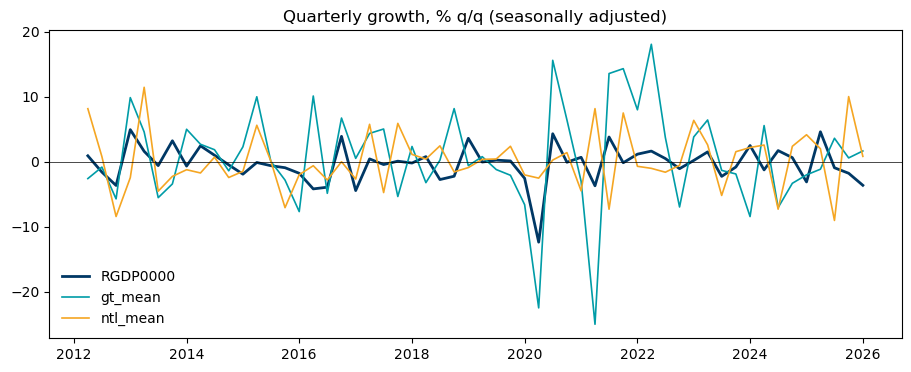

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
for col, color in [("RGDP0000", "#003865"), ("gt_mean", "#009CA7"), ("ntl_mean", "#F5A623")]:
    ax.plot(growth[col], label=col, color=color, lw=2 if col == "RGDP0000" else 1.2)
ax.axhline(0, color="black", lw=0.5)
ax.set_title("Quarterly growth, % q/q (seasonally adjusted)")
ax.legend(frameon=False);

In [18]:
growth.corr().round(2)

,RGDP0000,gt_mean,ntl_mean,brent
RGDP0000,1.00,0.49,0.06,0.25
gt_mean,0.49,1.00,0.02,0.39
ntl_mean,0.06,0.02,1.00,0.02
brent,0.25,0.39,0.02,1.00


## 7. A first OLS

$$\text{GDP growth}_t = \beta_0 + \beta_1\,\text{Google Trends}_t + \beta_2\,\text{NTL}_t + \varepsilon_t$$

In [19]:
import statsmodels.api as sm

d1 = growth[["RGDP0000", "gt_mean", "ntl_mean"]].dropna()
m1 = sm.OLS(d1["RGDP0000"], sm.add_constant(d1[["gt_mean", "ntl_mean"]])).fit()
print(f"{len(d1)} quarters, {d1.index.min().date()} -> {d1.index.max().date()}")
print(m1.summary())

56 quarters, 2012-04-01 -> 2026-01-01
                            OLS Regression Results                            
Dep. Variable:               RGDP0000   R-squared:                       0.241
Model:                            OLS   Adj. R-squared:                  0.213
Method:                 Least Squares   F-statistic:                     8.421
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           0.000667
Time:                        18:52:31   Log-Likelihood:                -129.34
No. Observations:                  56   AIC:                             264.7
Df Residuals:                      53   BIC:                             270.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

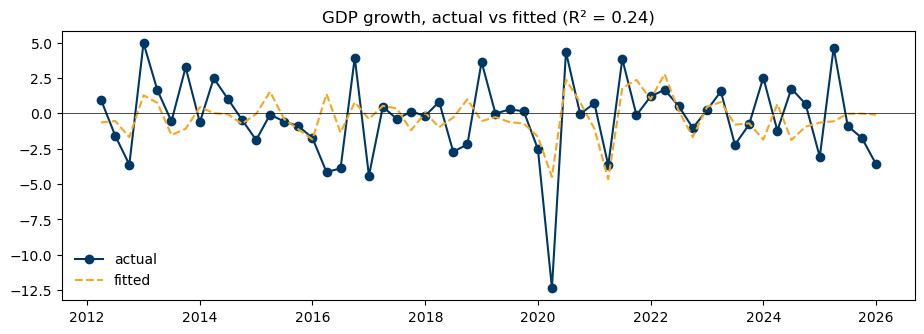

In [20]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(d1.index, d1["RGDP0000"], "o-", color="#003865", label="actual")
ax.plot(d1.index, m1.fittedvalues, "--", color="#F5A623", label="fitted")
ax.axhline(0, color="black", lw=0.5)
ax.set_title(f"GDP growth, actual vs fitted (R² = {m1.rsquared:.2f})")
ax.legend(frameon=False);

## 8. The question that matters: drop 2020

COVID-19 produced the largest quarterly swings in the sample. A regression can look
good simply because two or three quarters line up.

**Exercise 4.** Re-estimate the model without 2020 and compare the coefficients and R².

In [21]:
d2 = d1[d1.index.year != 2020]
m2 = sm.OLS(d2["RGDP0000"], sm.add_constant(d2[["gt_mean", "ntl_mean"]])).fit()
print(pd.DataFrame({"with 2020": m1.params, "without 2020": m2.params}).round(3))
print(f"R²: {m1.rsquared:.2f} with 2020, {m2.rsquared:.2f} without")

          with 2020  without 2020
const        -0.424        -0.190
gt_mean       0.179         0.090
ntl_mean      0.029         0.004
R²: 0.24 with 2020, 0.07 without


**Exercise 5.** Add `brent` to the regression (with and without 2020). Does the oil price
help more than the searches and the lights in an energy-heavy economy? Why might the
*same-quarter* oil price be a weak predictor of real (constant-price) GDP?

In [22]:
d3 = growth[["RGDP0000", "gt_mean", "ntl_mean", "brent"]].dropna()
m3 = sm.OLS(d3["RGDP0000"], sm.add_constant(d3[["gt_mean", "ntl_mean", "brent"]])).fit()
d4 = d3[d3.index.year != 2020]
m4 = sm.OLS(d4["RGDP0000"], sm.add_constant(d4[["gt_mean", "ntl_mean", "brent"]])).fit()
print(f"{len(d3)} quarters")
print(m3.summary().tables[1])
print(f"R²: {m3.rsquared:.2f} with 2020, {m4.rsquared:.2f} without")

56 quarters
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4230      0.339     -1.248      0.218      -1.103       0.257
gt_mean        0.1696      0.048      3.534      0.001       0.073       0.266
ntl_mean       0.0287      0.077      0.374      0.710      -0.125       0.182
brent          0.0112      0.024      0.477      0.635      -0.036       0.058
R²: 0.24 with 2020, 0.10 without


## Takeaways

- Seasonally adjust each series **at its own frequency** (12 for monthly, 4 for quarterly)
  *before* converting frequencies.
- One or two indicators rarely explain GDP growth in a commodity economy; the nowcast
  tool (Activities 10–11) chooses among ~500 series instead.
- Always check whether a relationship survives without the outlier quarters.